# Pipeline NLLB + LoRA — Traducteur multilingue Français · Anglais · Éwé

**Projet de groupe — GR02** · Master 1 IA-BD EPL S2 (Informatique et Gestion de données)

| Membres du groupe GR02 |
|---|
| AZIGLOSSOU Judith Gracia |
| NAPO NISSAO Rafia |
| WOGLO Koffi Boris Gilbride |
| PIO Sikirou Afeez Prince Cyrille |
| KOMBATE Gountande |

Sujet : *Traducteur Multilingue (Français, Anglais, Éwé) avec Reconnaissance Vocale* — proposé par Mme GBEDEVI.

---

Ce **notebook unique** regroupe tout le pipeline de traduction automatique demandé par le cahier des charges :

1. **Diagnostic GPU** — vérifier que CUDA est disponible avant l'entraînement.
2. **Préparation (optionnelle) du corpus** — import OPUS + Hugging Face, alignement, nettoyage.
3. **Exploration du corpus** — volumes par direction, contrôle du biais religieux.
4. **Fine-tuning LoRA** de `facebook/nllb-200-distilled-600M` sur les 6 directions (fr↔en, fr↔ewe, en↔ewe).
5. **Suivi des pertes** (train / validation) et courbes.
6. **Évaluation finale BLEU / chrF** par direction.
7. **Démo de traduction** sur l'adapter entraîné.

L'adapter LoRA final est sauvegardé dans `models/nllb-ewe-lora`, avec les rapports d'évaluation et le journal d'entraînement.


## 0. Mode d'emploi

1. Lancez ce notebook avec le kernel Python du projet: `.venv`.
2. Executez d'abord le diagnostic GPU. Si `torch.cuda.is_available()` vaut `False`, corrigez PyTorch CUDA avant de continuer.
3. Gardez `MODE = "smoke"` pour verifier que tout marche rapidement.
4. Passez a `MODE = "full"` pour le vrai fine-tuning.

Le notebook sauvegarde l'adapter LoRA dans `models/nllb-ewe-lora` et les rapports dans le meme dossier.

In [1]:
from pathlib import Path
import os
import sys
import subprocess
import time
import json

# --- Chemins du projet --------------------------------------------------------
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT / "src"))

DATA_DIR = PROJECT_ROOT / "data" / "processed" / "nllb"
# Train AUGMENTE par back-translation (cf. scripts/make_backtranslation.py) :
# donnees propres + paires synthetiques (en->ewe et fr->ewe, cible ewe humaine).
# Le valid/test restent les fichiers d'origine -> scores comparables, pas de fuite.
TRAIN_CSV = DATA_DIR / "nllb_train.csv"
VALID_CSV = DATA_DIR / "nllb_valid.csv"
TEST_CSV = DATA_DIR / "nllb_test.csv"
SUMMARY_CSV = DATA_DIR / "nllb_summary.csv"

MODEL_NAME = "facebook/nllb-200-distilled-600M"
OUTPUT_DIR = PROJECT_ROOT / "models" / "nllb-ewe-lora"

# --- Configuration de l'execution --------------------------------------------
# MODE = "smoke" : test rapide de bout en bout (quelques minutes) pour verifier
#                  que tout le pipeline fonctionne.
# MODE = "full"  : vrai fine-tuning sur l'ensemble du corpus.
MODE = "full"
REQUIRE_CUDA = True          # bloque l'entrainement si CUDA est indisponible
RUN_DATA_PREPARATION = False  # True pour (re)generer le dataset depuis les scripts

# Les hyperparametres s'adaptent automatiquement au MODE choisi.
IS_SMOKE = MODE == "smoke"
MAX_TRAIN_SAMPLES = 512 if IS_SMOKE else 200000   # +data : on exploite beaucoup plus le corpus ewe
MAX_VALID_SAMPLES = 128 if IS_SMOKE else 6000
MAX_EVAL_PER_DIRECTION = 20 if IS_SMOKE else 200  # eval plus fiable par direction
EPOCHS = 0.05 if IS_SMOKE else 2.0                # 2 epochs : la val loss plafonne des l'epoch 2
# Gros batch pour saturer le GPU (RTX 5080 16 Go, bf16, gradient checkpointing).
# Si CUDA out of memory : repasser TRAIN_BATCH_SIZE/EVAL_BATCH_SIZE a 16.
TRAIN_BATCH_SIZE = 32
EVAL_BATCH_SIZE = 32
GRADIENT_ACCUMULATION_STEPS = 2   # batch effectif = 32 x 2 = 64 -> gradients plus stables
MAX_SOURCE_LENGTH = 128
MAX_TARGET_LENGTH = 128
LEARNING_RATE = 2e-4

print("Projet:", PROJECT_ROOT)
print("Train:", TRAIN_CSV.name, "| echantillon:", MAX_TRAIN_SAMPLES, "| epochs:", EPOCHS)
print("Batch effectif:", TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS)
print("Sortie LoRA:", OUTPUT_DIR)


Projet: D:\python\traducteur-fr-en-ewe
Train: nllb_train.csv | echantillon: 200000 | epochs: 2.0
Batch effectif: 64
Sortie LoRA: D:\python\traducteur-fr-en-ewe\models\nllb-ewe-lora


## 1. Diagnostic GPU

Si Windows voit le GPU mais que cette cellule affiche `cuda_available = False`, le probleme vient presque toujours d'une installation PyTorch CPU-only.

In [2]:
import torch

print("torch:", torch.__version__)
print("cuda_available:", torch.cuda.is_available())
print("torch_cuda_runtime:", torch.version.cuda)
print("device_count:", torch.cuda.device_count())
if torch.cuda.is_available():
    print("device_name:", torch.cuda.get_device_name(0))
    print("bf16_supported:", torch.cuda.is_bf16_supported())
    torch.set_float32_matmul_precision("high")
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
else:
    print("Commande conseillee:")
    print("python -m pip uninstall -y torch torchvision torchaudio")
    print("python -m pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu128")

if REQUIRE_CUDA and not torch.cuda.is_available():
    raise RuntimeError("CUDA indisponible dans cet environnement Python. Installez PyTorch CUDA avant l'entrainement.")

torch: 2.11.0+cu130
cuda_available: True
torch_cuda_runtime: 13.0
device_count: 1
device_name: NVIDIA GeForce RTX 5080 Laptop GPU
bf16_supported: True


## 2. Preparation optionnelle du dataset

Cette cellule reste optionnelle. Si `data/processed/nllb/nllb_train.csv` existe deja, laissez `RUN_DATA_PREPARATION = False`.

In [3]:
if RUN_DATA_PREPARATION:
    commands = [
        [sys.executable, "scripts/download_opus_parallel.py", "--source", "recommended"],
        [
            sys.executable,
            "scripts/import_hf_parallel_dataset.py",
            "--dataset", "ghananlpcommunity/english-ewe-sentence-pairs-4m",
            "--src-column", "English",
            "--tgt-column", "Ewe",
            "--src-lang", "eng",
            "--tgt-lang", "ewe",
            "--min-quality", "0.80",
            "--max-rows", "120000",
            "--output", "data/processed/hf/ghana_en_ewe.csv",
        ],
        [
            sys.executable,
            "scripts/prepare_nllb_training_data.py",
            "--inputs",
            "data/processed/opus/nllb_ee_fr.csv",
            "data/processed/opus/translatewiki_ee_fr.csv",
            "data/processed/opus/ted2020_en_fr.csv",
            "data/processed/opus/news_commentary_en_fr.csv",
            "data/processed/opus/tatoeba_en_fr.csv",
            "data/processed/hf/ghana_en_ewe.csv",
            "--output-dir", "data/processed/nllb",
            "--max-per-direction", "120000",
        ],
    ]
    for command in commands:
        print("$", " ".join(command))
        subprocess.run(command, check=True)
else:
    print("Preparation ignoree. Les fichiers existants seront utilises.")

for path in [TRAIN_CSV, VALID_CSV, TEST_CSV, SUMMARY_CSV]:
    if not path.exists():
        raise FileNotFoundError(f"Fichier manquant: {path}")
    print(path.relative_to(PROJECT_ROOT), "OK")

Preparation ignoree. Les fichiers existants seront utilises.
data\processed\nllb\nllb_train.csv OK
data\processed\nllb\nllb_valid.csv OK
data\processed\nllb\nllb_test.csv OK
data\processed\nllb\nllb_summary.csv OK


## 3. Exploration du corpus final

On verifie ici les volumes, les directions et l'absence de corpus religieux dans le dataset d'entrainement.

,split,src_lang,tgt_lang,domain,is_religious,rows
0,test,eng,ewe,web-mined,False,107
1,test,eng,fra,daily,False,794
2,test,eng,fra,news,False,426
3,test,eng,fra,talks,False,1155
4,test,ewe,eng,web-mined,False,111
5,test,ewe,fra,software,False,5
6,test,ewe,fra,web-mined,False,2383
7,test,fra,eng,daily,False,741
8,test,fra,eng,news,False,457
9,test,fra,eng,talks,False,1203


Lignes religieuses: 0


,split,src_lang,tgt_lang,rows
0,test,eng,ewe,107
1,test,eng,fra,2375
2,test,ewe,eng,111
3,test,ewe,fra,2388
4,test,fra,eng,2401
5,test,fra,ewe,2357
6,train,eng,ewe,5603
7,train,eng,fra,115227
8,train,ewe,eng,5588
9,train,ewe,fra,115168


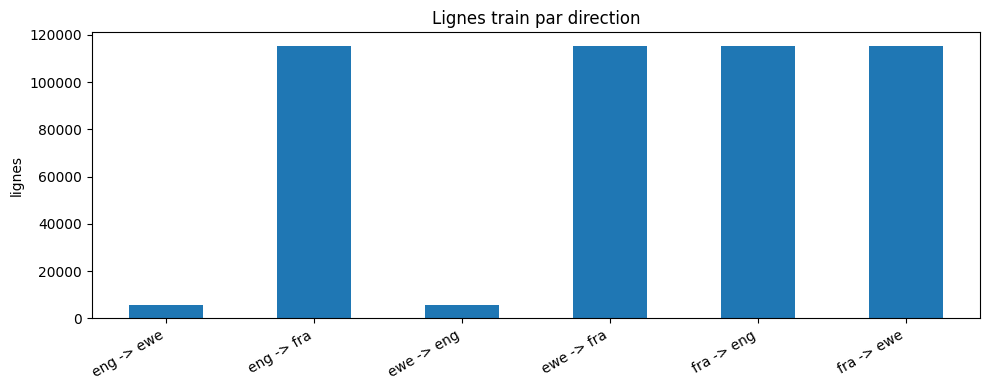

In [4]:
import pandas as pd

summary = pd.read_csv(SUMMARY_CSV)
display(summary)

religious_rows = int(summary.loc[summary["is_religious"] == True, "rows"].sum()) if (summary["is_religious"] == True).any() else 0
print("Lignes religieuses:", religious_rows)

direction_summary = summary.groupby(["split", "src_lang", "tgt_lang"], as_index=False)["rows"].sum()
display(direction_summary)

try:
    import matplotlib.pyplot as plt
    train_counts = direction_summary[direction_summary["split"] == "train"].copy()
    train_counts["direction"] = train_counts["src_lang"] + " -> " + train_counts["tgt_lang"]
    ax = train_counts.plot.bar(x="direction", y="rows", legend=False, figsize=(10, 4), title="Lignes train par direction")
    ax.set_xlabel("")
    ax.set_ylabel("lignes")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
except Exception as exc:
    print("Graphique non affiche:", exc)

## 4. Chargement des donnees pour l'entrainement

En mode `smoke`, on prend un petit echantillon. En mode `full`, on utilise tout le corpus.

In [5]:
def read_training_csv(path, max_samples=None):
    df = pd.read_csv(path)
    df["src_text"] = df["src_text"].fillna("").astype(str).str.strip()
    df["tgt_text"] = df["tgt_text"].fillna("").astype(str).str.strip()
    df = df[(df["src_text"].str.len() > 0) & (df["tgt_text"].str.len() > 0)]
    if max_samples:
        df = df.sample(n=min(max_samples, len(df)), random_state=42)
    return df.reset_index(drop=True)

train_df = read_training_csv(TRAIN_CSV, MAX_TRAIN_SAMPLES)
valid_df = read_training_csv(VALID_CSV, MAX_VALID_SAMPLES)

print("train:", len(train_df), "valid:", len(valid_df))
display(train_df[["src_lang", "tgt_lang", "src_lang_nllb", "tgt_lang_nllb", "src_text", "tgt_text", "source"]].head(8))

train: 200000 valid: 6000


,src_lang,tgt_lang,src_lang_nllb,tgt_lang_nllb,src_text,tgt_text,source
0,eng,fra,eng_Latn,fra_Latn,Researchers call the 20s an extended adolescence.,"Les chercheurs appellent les 20 ans, une adole...",opus:ted2020:v1:en-fr
1,ewe,fra,ewe_Latn,fra_Latn,Le esia ta Biblia te gbe ɖe alesi wòhiãe be mí...,"La pratique doit être équilibrée, dans le rapp...",opus:nllb:v1:ee-fr
2,eng,fra,eng_Latn,fra_Latn,I don't feel like meeting her now.,Je n'ai pas envie de la voir maintenant.,opus:tatoeba:v2023-04-12:en-fr
3,ewe,fra,ewe_Latn,fra_Latn,"Elabena Amegbetɔvi la va be, wòaɖe nusiwo bu la.",""" En effet, le Fils de l'homme est venu cherch...",opus:nllb:v1:ee-fr
4,fra,eng,fra_Latn,eng_Latn,Si je ne pouvais pas utiliser de cheville pour...,If I couldn't use an ankle joint to achieve th...,opus:ted2020:v1:en-fr
5,fra,ewe,fra_Latn,ewe_Latn,Qu'est-il arrivé au malheureux ?,Nukae adzɔ ɖe ame vɔ̃ɖiwo dzi?,opus:nllb:v1:ee-fr
6,fra,eng,fra_Latn,eng_Latn,"Ces mesures protégeront notre environnement, m...",Such efforts would not just protect our enviro...,opus:news-commentary:v16:en-fr
7,fra,ewe,fra_Latn,ewe_Latn,Ils ont besoin d'un bon avocat.,Ðe Aɖaŋuɖoɖo Nyui Xɔxɔ Hiã?,opus:nllb:v1:ee-fr


## 5. Modele NLLB + LoRA

On charge NLLB, puis on ajoute des matrices LoRA sur les projections d'attention `q_proj` et `v_proj`.

In [6]:
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, DataCollatorForSeq2Seq
from transformers import Seq2SeqTrainer, Seq2SeqTrainingArguments
from peft import LoraConfig, TaskType, get_peft_model

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
base_model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)

# On retire max_length de la config de generation : on pilotera la longueur
# uniquement via max_new_tokens (supprime le warning max_new_tokens/max_length).
base_model.generation_config.max_length = None

if MODE == "full":
    base_model.gradient_checkpointing_enable()
    base_model.config.use_cache = False

# LoRA plus capacitaire : rang double + on adapte TOUTES les projections
# d'attention ET les couches feed-forward. Indispensable pour que le decodeur
# apprenne reellement a GENERER de l'ewe (langue peu dotee), pas seulement a
# ajuster du fr/en deja connu.
lora_config = LoraConfig(
    task_type=TaskType.SEQ_2_SEQ_LM,
    r=32,
    lora_alpha=64,
    lora_dropout=0.05,
    target_modules=["q_proj", "k_proj", "v_proj", "out_proj", "fc1", "fc2"],
)
model = get_peft_model(base_model, lora_config)
model.print_trainable_parameters()

D:\python\traducteur-fr-en-ewe\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 512/512 [00:00<00:00, 23519.63it/s]


trainable params: 17,301,504 || all params: 632,375,296 || trainable%: 2.7360


## 6. Tokenisation NLLB multidirectionnelle

Chaque ligne porte deja `src_lang_nllb` et `tgt_lang_nllb`. Le tokenizer NLLB utilise ces codes pour injecter la bonne langue source et la bonne cible.

In [ ]:
def preprocess(example):
    tokenizer.src_lang = example["src_lang_nllb"]
    tokenizer.tgt_lang = example["tgt_lang_nllb"]
    model_inputs = tokenizer(
        example["src_text"],
        max_length=MAX_SOURCE_LENGTH,
        truncation=True,
    )
    labels = tokenizer(
        text_target=example["tgt_text"],
        max_length=MAX_TARGET_LENGTH,
        truncation=True,
    )
    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

train_ds = Dataset.from_pandas(train_df, preserve_index=False).map(
    preprocess,
    remove_columns=train_df.columns.tolist(),
    desc="Tokenisation train",
)
valid_ds = Dataset.from_pandas(valid_df, preserve_index=False).map(
    preprocess,
    remove_columns=valid_df.columns.tolist(),
    desc="Tokenisation valid",
)

collator = DataCollatorForSeq2Seq(tokenizer=tokenizer, model=model)
print(train_ds)
print(valid_ds)

Tokenisation train:  88%|████████▊ | 176704/200000 [00:48<00:04, 5593.65 examples/s]

## 7. Entrainement avec suivi des pertes

Pendant l'entrainement, le Trainer affiche `loss`, `grad_norm`, `learning_rate` et `eval_loss`. Apres la cellule, on transforme l'historique en tableau et en courbes.

In [ ]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

use_bf16 = torch.cuda.is_available() and torch.cuda.is_bf16_supported()
use_fp16 = torch.cuda.is_available() and not use_bf16

# eval et save alignes pour pouvoir recharger le meilleur checkpoint.
eval_steps = 25 if MODE == "smoke" else 1000
save_steps = 50 if MODE == "smoke" else 1000
logging_steps = 5 if MODE == "smoke" else 50

# --- Vitesse -----------------------------------------------------------------
# Windows + Jupyter : dataloader_num_workers > 0 utilise le multiprocessing
# "spawn" et peut FIGER au demarrage. Si l'entrainement ne demarre pas, repasser
# DATALOADER_WORKERS a 0.
DATALOADER_WORKERS = 4

training_args = Seq2SeqTrainingArguments(
    output_dir=str(OUTPUT_DIR),
    learning_rate=LEARNING_RATE,
    per_device_train_batch_size=TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=EVAL_BATCH_SIZE,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
    num_train_epochs=EPOCHS,
    warmup_ratio=0.03,
    fp16=use_fp16,
    bf16=use_bf16,
    eval_strategy="steps",
    save_strategy="steps",
    eval_steps=eval_steps,
    save_steps=save_steps,
    logging_steps=logging_steps,
    save_total_limit=3,
    predict_with_generate=False,
    report_to="none",
    # VITESSE : regroupe les phrases de longueur proche -> beaucoup moins de
    # tokens de padding inutiles -> plus de calcul utile par step (gain net sans
    # perte de qualite). pin_memory + workers gardent le GPU alimente.
    group_by_length=True,
    dataloader_num_workers=DATALOADER_WORKERS,
    dataloader_pin_memory=True,
    # On garde le meilleur modele (eval_loss minimale) plutot que le dernier :
    # protege contre un eventuel sur-apprentissage.
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
)

trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=valid_ds,
    processing_class=tokenizer,
    data_collator=collator,
)

start = time.time()
train_result = trainer.train()
elapsed = time.time() - start
trainer.save_model(str(OUTPUT_DIR))
tokenizer.save_pretrained(str(OUTPUT_DIR))

print("Temps entrainement minutes:", round(elapsed / 60, 2))
print("Adapter sauvegarde dans:", OUTPUT_DIR)

## 8. Courbes et historique d'entrainement

Cette section affiche les metriques collectees pendant le fine-tuning.

In [ ]:
history = pd.DataFrame(trainer.state.log_history)
history_path = OUTPUT_DIR / "training_log.csv"
history.to_csv(history_path, index=False)
display(history.tail(20))
print("Historique sauvegarde:", history_path)

try:
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    if "loss" in history:
        history.dropna(subset=["loss"]).plot(x="step", y="loss", ax=axes[0], title="Train loss")
    if "eval_loss" in history:
        history.dropna(subset=["eval_loss"]).plot(x="step", y="eval_loss", ax=axes[1], title="Validation loss")
    plt.tight_layout()
except Exception as exc:
    print("Graphiques non affiches:", exc)

## 9. Evaluation finale BLEU / chrF

On genere des traductions sur `nllb_test.csv`, par direction, puis on calcule BLEU et chrF. Les metriques de generation sont plus lentes que `eval_loss`, donc on limite le nombre d'exemples par direction.

In [ ]:
from sacrebleu import corpus_bleu, corpus_chrf

test_df = pd.read_csv(TEST_CSV)
model.eval()

def batched(values, size):
    for start_index in range(0, len(values), size):
        yield values[start_index:start_index + size]

def generate_for_group(group, batch_size=16):
    tokenizer.src_lang = group.iloc[0]["src_lang_nllb"]
    forced_bos_token_id = tokenizer.convert_tokens_to_ids(group.iloc[0]["tgt_lang_nllb"])
    predictions = []
    texts = group["src_text"].tolist()
    device = model.device
    with torch.no_grad():
        for batch in batched(texts, batch_size):
            encoded = tokenizer(
                batch,
                return_tensors="pt",
                padding=True,
                truncation=True,
                max_length=MAX_SOURCE_LENGTH,
            ).to(device)
            generated = model.generate(
                **encoded,
                forced_bos_token_id=forced_bos_token_id,
                max_new_tokens=MAX_TARGET_LENGTH,
                num_beams=4,
            )
            predictions.extend(tokenizer.batch_decode(generated, skip_special_tokens=True))
    return predictions

reports = []
examples = []
all_eval = {}  # (src_lang, tgt_lang) -> {pred, ref, src} : sert aux graphes (section 9b)
for (src_lang, tgt_lang), group in test_df.groupby(["src_lang", "tgt_lang"], sort=True):
    group = group.sample(n=min(MAX_EVAL_PER_DIRECTION, len(group)), random_state=42).reset_index(drop=True)
    predictions = generate_for_group(group, batch_size=16)
    references = group["tgt_text"].tolist()
    all_eval[(src_lang, tgt_lang)] = {
        "pred": predictions,
        "ref": references,
        "src": group["src_text"].tolist(),
    }
    reports.append({
        "src_lang": src_lang,
        "tgt_lang": tgt_lang,
        "rows": len(group),
        "bleu": round(float(corpus_bleu(predictions, [references]).score), 4),
        "chrf": round(float(corpus_chrf(predictions, [references]).score), 4),
    })
    for i in range(min(5, len(group))):
        examples.append({
            "src_lang": src_lang,
            "tgt_lang": tgt_lang,
            "src_text": group.loc[i, "src_text"],
            "reference": references[i],
            "prediction": predictions[i],
        })

report_df = pd.DataFrame(reports)
examples_df = pd.DataFrame(examples)
report_path = OUTPUT_DIR / "evaluation_report.csv"
examples_path = OUTPUT_DIR / "evaluation_examples.csv"
report_df.to_csv(report_path, index=False)
examples_df.to_csv(examples_path, index=False)

display(report_df)
display(examples_df)
print("Rapport:", report_path)
print("Exemples:", examples_path)

## 9b. Graphes d'évaluation détaillés

Visualisation des scores de la section 9 (calculés sur le **test held-out**, jamais vu à l'entraînement) :

1. **BLEU et chrF par direction** — la qualité réelle de chaque sens de traduction.
2. **Taux d'off-target vers l'éwé** — part des prédictions censées être en éwé qui ne contiennent aucun caractère spécifique éwé (signal d'hallucination / sortie dans la mauvaise langue, surtout sur les directions peu dotées en↔ewe).
3. **Distribution des longueurs de prédiction** — détecte les sorties tronquées ou répétitives.

> Nécessite `matplotlib` : `.venv\Scripts\python.exe -m pip install matplotlib`

In [ ]:
import matplotlib.pyplot as plt

# matplotlib (police DejaVu Sans par defaut) gere les caracteres ewe ɖ ƒ ŋ ɔ ɛ ɣ ʋ.

# Directions ordonnees pour des graphes lisibles.
plot_df = report_df.copy()
plot_df["direction"] = plot_df["src_lang"] + "→" + plot_df["tgt_lang"]
plot_df = plot_df.sort_values("direction").reset_index(drop=True)

# 1) BLEU et chrF par direction --------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric, color in zip(axes, ["bleu", "chrf"], ["#4C72B0", "#55A868"]):
    bars = ax.bar(plot_df["direction"], plot_df[metric], color=color)
    ax.set_title(f"{metric.upper()} par direction")
    ax.set_xlabel("direction")
    ax.set_ylabel(metric.upper())
    ax.tick_params(axis="x", rotation=45)
    ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=8)
plt.tight_layout()
plt.show()

# 2) Taux d'off-target vers l'ewe -----------------------------------------------
# Proportion de predictions censees etre en ewe qui ne contiennent AUCUN caractere
# ewe specifique => quasi surement de l'anglais/off-target (cf. saga de nettoyage).
EWE_CHARS = set("ɖƒŋɔɛɣʋãẽĩõũƉƑŊƆƐƔƲ")
off_rows = []
for (sl, tl), d in all_eval.items():
    if tl == "ewe":
        preds = d["pred"]
        off = sum(1 for p in preds if not any(c in EWE_CHARS for c in str(p))) / max(len(preds), 1)
        off_rows.append({"direction": f"{sl}→{tl}", "off_target_pct": round(100 * off, 1)})
if off_rows:
    off_df = pd.DataFrame(off_rows).sort_values("direction").reset_index(drop=True)
    display(off_df)
    fig, ax = plt.subplots(figsize=(7, 4))
    bars = ax.bar(off_df["direction"], off_df["off_target_pct"], color="#C44E52")
    ax.set_title("Off-target vers l'éwé (prédiction sans caractère éwé)")
    ax.set_ylabel("% de prédictions suspectes")
    ax.set_ylim(0, 100)
    ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=8)
    plt.tight_layout()
    plt.show()

# 3) Distribution des longueurs de prediction par direction ---------------------
fig, ax = plt.subplots(figsize=(10, 5))
for (sl, tl), d in sorted(all_eval.items()):
    lengths = [len(str(p)) for p in d["pred"]]
    ax.hist(lengths, bins=25, alpha=0.4, label=f"{sl}→{tl}")
ax.set_title("Distribution des longueurs de prédiction (caractères)")
ax.set_xlabel("longueur (caractères)")
ax.set_ylabel("nombre d'exemples")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 10. Demo de traduction

Cette cellule permet de tester rapidement l'adapter LoRA charge en memoire.

In [ ]:
LANG_TO_NLLB = {"fra": "fra_Latn", "eng": "eng_Latn", "ewe": "ewe_Latn"}

def translate_text(text, source_lang="fra", target_lang="ewe", max_new_tokens=128):
    model.eval()
    tokenizer.src_lang = LANG_TO_NLLB[source_lang]
    forced_bos_token_id = tokenizer.convert_tokens_to_ids(LANG_TO_NLLB[target_lang])
    encoded = tokenizer(text, return_tensors="pt", truncation=True, max_length=MAX_SOURCE_LENGTH).to(model.device)
    with torch.no_grad():
        generated = model.generate(
            **encoded,
            forced_bos_token_id=forced_bos_token_id,
            max_new_tokens=max_new_tokens,
            num_beams=4,
        )
    return tokenizer.batch_decode(generated, skip_special_tokens=True)[0]

tests = [
    ("Bonjour, comment vas-tu ?", "fra", "ewe"),
    ("I am going to school tomorrow.", "eng", "ewe"),
    ("Je vais bien.", "fra", "eng"),
]

for text, src, tgt in tests:
    print(f"{src} -> {tgt}: {text}")
    print("=>", translate_text(text, src, tgt))
    print()